In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

transactions = pd.read_csv("../data/transactions.csv", nrows=1000000, sep=",")
gender_train = pd.read_csv("../data/gender_train.csv", sep=",")
tr_mcc_codes = pd.read_csv("../data/tr_mcc_codes.csv", sep=";")
tr_types = pd.read_csv("../data/tr_types.csv", sep=";")

data = transactions.merge(gender_train, on="customer_id", how="left")
data = data.merge(tr_mcc_codes, on="mcc_code", how="inner")
data = data.merge(tr_types, on="tr_type", how="inner")

print(f"Датафрейм: {data.shape[0]} строк")

Датафрейм: 999584 строк


In [18]:
expenses = data.loc[data['amount'] < 0, 'amount']

data['amount_bucket'] = pd.qcut(expenses, q=4, labels=['Very High', 'High', 'Middle', 'Low'])

print(data['amount_bucket'])
data['amount_bucket'] = data['amount_bucket'].cat.add_categories('Income')
data['amount_bucket'] = data['amount_bucket'].fillna('Income')


0               Low
1               NaN
2         Very High
3               Low
4               Low
            ...    
999579         High
999580    Very High
999581         High
999582         High
999583       Middle
Name: amount_bucket, Length: 999584, dtype: category
Categories (4, str): ['Very High' < 'High' < 'Middle' < 'Low']


In [14]:
# 153 10:24:00
data['Hour'] = data['tr_datetime'].str.split(' ').str[1].str.split(':').str[0].astype(int)

pivot_table = data.pivot_table(
    index='Hour', 
    columns='amount_bucket', 
    values='gender', 
    aggfunc='mean'
)

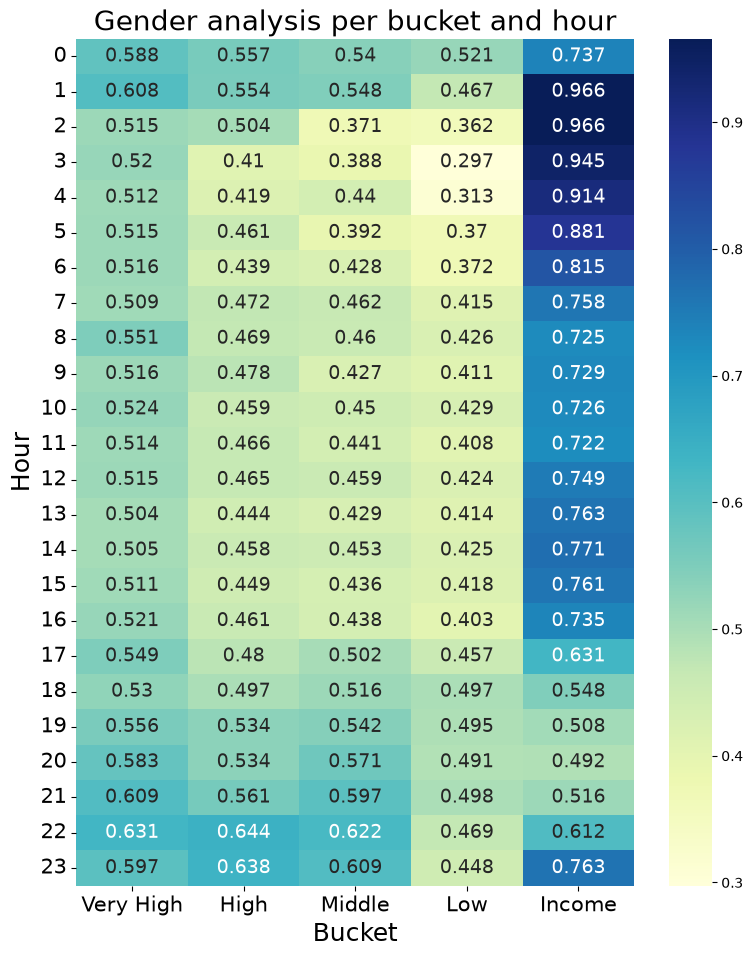

In [15]:
def plot_pivot_table(pivot_table):
    plt.figure(figsize=(9, 11))
    sns.heatmap(pivot_table, cmap="YlGnBu", annot=True, 
                fmt='.3g', annot_kws={"size": 14})
    plt.xticks(fontsize=15)
    plt.yticks(rotation=0, fontsize=15)
    plt.xlabel('Bucket', size=18)
    plt.ylabel('Hour', fontsize=18)
    plt.title('Gender analysis per bucket and hour', fontsize=20)
    plt.show()

plot_pivot_table(pivot_table)